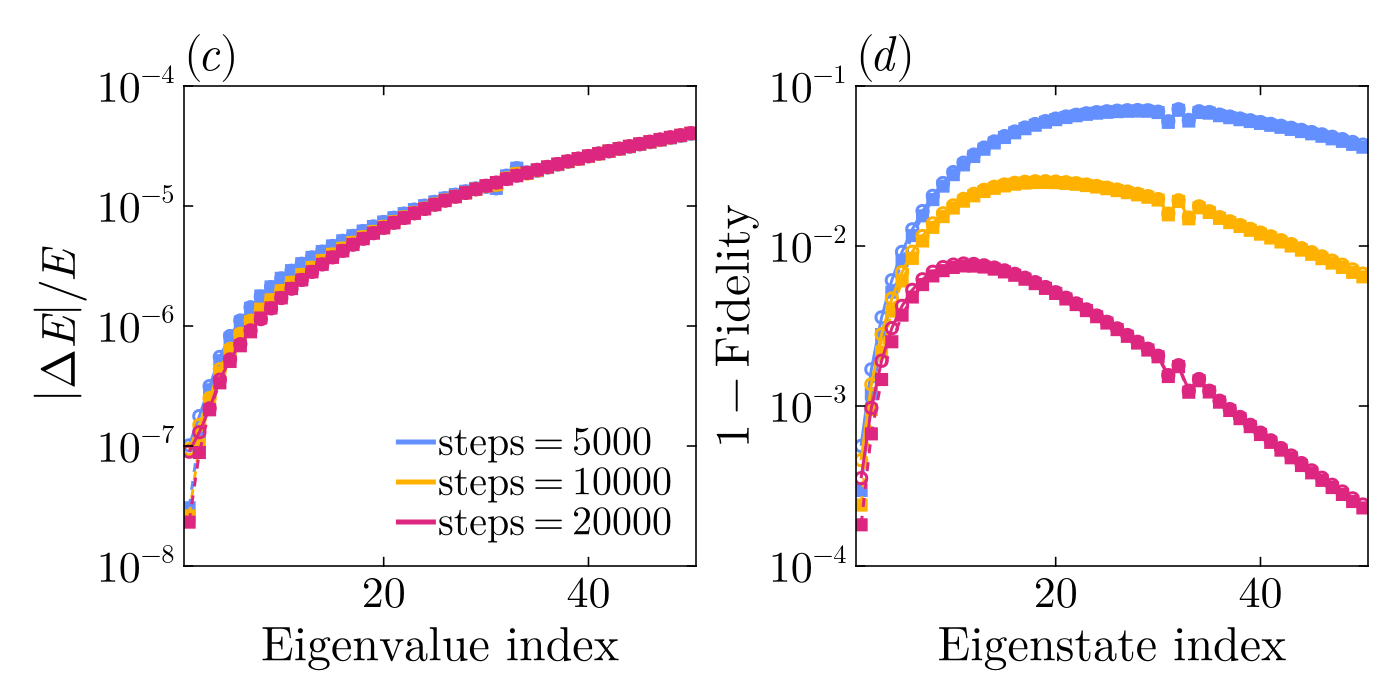

In [1]:
using CairoMakie, DataFrames, XLSX, LaTeXStrings

CairoMakie.set_theme!(Theme(
    fontsize = 11,
    font = "Times New Roman",
    Axis = (
        xgridvisible = false, ygridvisible = false,
        xlabelsize = 24, ylabelsize = 24, titlesize = 24,
        xticklabelsize = 22, yticklabelsize = 22,
        spinewidth = 0.8, xtickwidth = 0.8, ytickwidth = 0.8,
        xticksize = 5, yticksize = 5,
        xminorticksvisible = false, yminorticksvisible = false,
        ticklabelfont = "Times New Roman",
        labelfont = "Times New Roman",
        titlefont = "Times New Roman",
        xtickalign = 1, ytickalign = 1,
        xticksmirrored = true, yticksmirrored = true,
    ),
))

file = "anharmonic_oscillator_data.xlsx"

palette = [RGBf(0.392, 0.561, 1.0), RGBf(1.0, 0.694, 0.0), RGBf(0.867, 0.149, 0.498)]

style = (X = (marker = :circle, linestyle = :solid, filled = false),
         Y = (marker = :rect,   linestyle = :dash,  filled = true))

floorlog(v) = max.(Float64.(v), 1e-16)

function set_log_yticks!(ax, es)
    ax.yticks = (10.0 .^ es, [latexstring("10^{", e, "}") for e in es])
    ylims!(ax, 10.0^first(es), 10.0^last(es))
end

function set_xticks!(ax, ticks, lo, hi)
    ax.xticks = (ticks, [latexstring(t) for t in ticks])
    xlims!(ax, lo, hi)
end

function make_fig(sheets, labels, titles; err_yticks, fid_yticks, msize, xlo, xhi, xy_legend, savepath)
    fig = Figure(size = (700, 350), backgroundcolor = :white)

    axe = Axis(fig[1, 1], xlabel = L"Eigenvalue index$$", ylabel = L"$\left|\Delta E\right|/E$",
               yscale = log10, title = titles[1], titlealign = :left, titlegap = 2)
    axf = Axis(fig[1, 2], xlabel = L"Eigenstate index$$", ylabel = L"1-\mathrm{Fidelity}",
               yscale = log10, title = titles[2], titlealign = :left, titlegap = 2)

    for (i, sheet) in enumerate(sheets)
        df  = DataFrame(XLSX.readtable(file, sheet))
        xs  = Float64.(df.index)
        col = palette[i]
        for a in (:X, :Y), (ax, name) in ((axe, "relE_$a"), (axf, "1-F_$a"))
            st = style[a]
            y  = floorlog(df[!, name])
            lines!(ax, xs, y; color = col, linewidth = 1.5, linestyle = st.linestyle)
            scatter!(ax, xs, y; color = st.filled ? col : :transparent,
                     marker = st.marker, markersize = msize,
                     strokecolor = col, strokewidth = 1.5)
        end
    end

    set_log_yticks!(axe, err_yticks)
    set_log_yticks!(axf, fid_yticks)
    set_xticks!(axe, [0, 20, 40], xlo, xhi)
    set_xticks!(axf, [0, 20, 40], xlo, xhi)

    color_els = [[LineElement(color = palette[i], linewidth = 2.5)] for i in eachindex(sheets)]

    if xy_legend
        xy_els = [
            [LineElement(color = :black, linestyle = :solid, linewidth = 1.5),
             MarkerElement(color = :transparent, marker = :circle, markersize = 10,
                           strokecolor = :black, strokewidth = 1.5)],
            [LineElement(color = :black, linestyle = :dash, linewidth = 1.5),
             MarkerElement(color = :black, marker = :rect, markersize = 10,
                           strokecolor = :black, strokewidth = 1.5)],
        ]
        axislegend(axf, [color_els, xy_els], [labels, [L"X", L"Y"]], ["", ""];
                   position = :rb, labelsize = 15, framevisible = false,
                   patchlabelgap = 1, rowgap = 0)
    else
        axislegend(axe, color_els, labels;
                   position = :rb, labelsize = 20, framevisible = false,
                   patchlabelgap = 1, rowgap = 0)
    end

    colgap!(fig.layout, 8)
    save(savepath, fig)
    return fig
end


runs1 = [(0.5, 2000), (0.25, 4000), (0.1, 10000)]

fig1 = make_fig(
    ["code1_dt$(dt)_steps$(K)" for (dt, K) in runs1],
    [latexstring("\\Delta t=", dt, ",\\ \\mathrm{steps}=", K) for (dt, K) in runs1],
    (L"(a)", L"(b)");
    err_yticks = [-8, -6, -4, -2],
    fid_yticks = [-7, -5, -3, -1],
    msize = 6, xlo = 0, xhi = 51,
    xy_legend = true,
    savepath = "2D_AnhO_PRL.pdf",
)


runs2 = [5000, 10000, 20000]

fig2 = make_fig(
    ["code2_dt0.1_steps$(s)" for s in runs2],
    [latexstring("\\mathrm{steps}=", s) for s in runs2],
    (L"(c)", L"(d)");
    err_yticks = [-8, -7, -6, -5, -4],
    fid_yticks = [-4, -3, -2, -1],
    msize = 8, xlo = 0.5, xhi = 50.5,
    xy_legend = false,
    savepath = "2D_Anharmonic_Oscillator_PRL2.pdf",
)

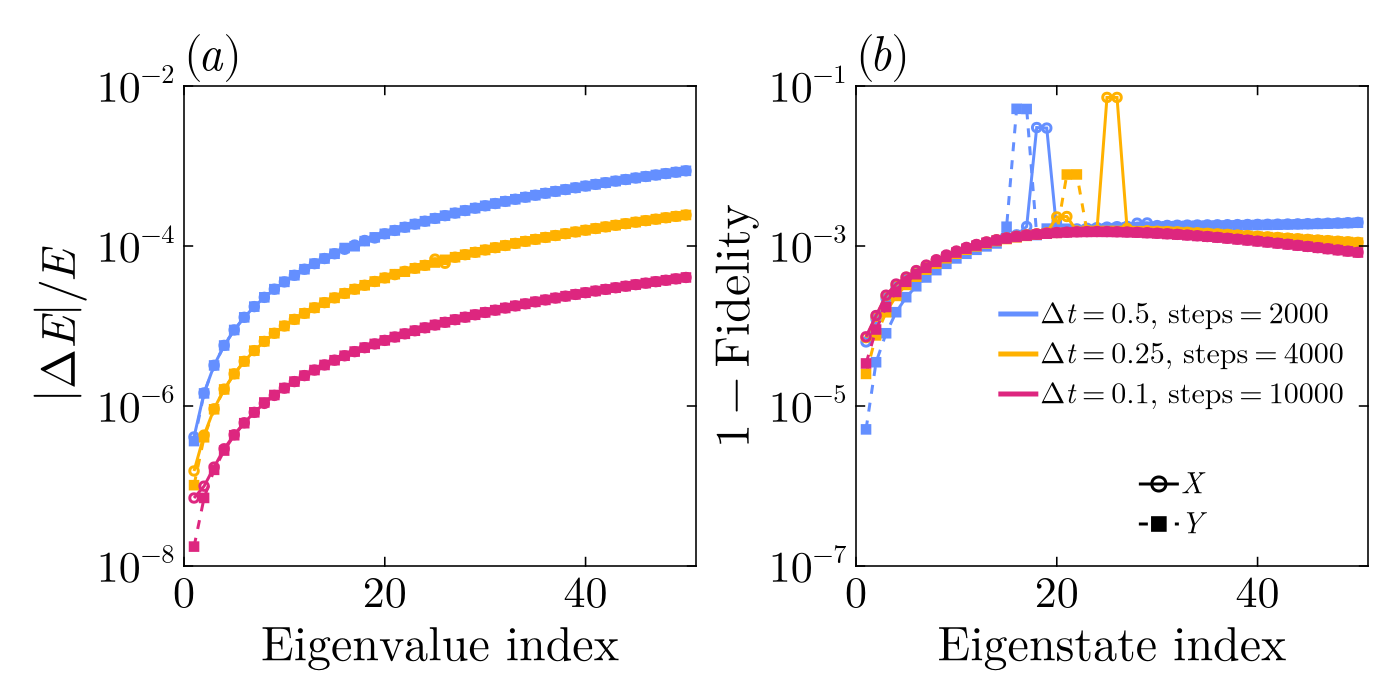

In [2]:
fig1